In [40]:
class SimpleReflexAgent:
    def __init__(self, rules):
        """
        Initializes the SimpleReflexAgent with a set of rules.
        Each rule is a tuple: (condition_function, action_function).
        condition_function takes a perception and returns True/False.
        action_function takes a perception and returns an action.
        """
        self.rules = rules

    def perceive_and_act(self, perception):
        """
        Perceives the environment and chooses an action based on rules.
        """
        for condition_function, action_function in self.rules:
            if condition_function(perception):
                return action_function(perception)
        return "No action"  # Default if no rule applies

# Define example rules
def is_dirty(perception):
    return "dirt" in perception

def clean_action(perception):
    return "Clean the floor"

def is_obstacle(perception):
    return "obstacle" in perception

def avoid_obstacle_action(perception):
    return "Move around obstacle"

# Create an agent instance
# The rules are defined as a list of (condition, action) pairs
agent_rules = [
    (is_dirty, clean_action),
    (is_obstacle, avoid_obstacle_action)
]
vacuum_agent = SimpleReflexAgent(agent_rules)

# Simulate perceptions and agent actions
perceptions = [
    {"location": "A", "state": "clean"},
    {"location": "B", "state": "dirty", "dirt": True},
    {"location": "C", "state": "clean", "obstacle": True},
    {"location": "D", "state": "dirty", "dirt": True, "obstacle": True}
]

for i, p in enumerate(perceptions):
    action = vacuum_agent.perceive_and_act(p)
    print(f"Perception {i+1}: {p}")
    print(f"Agent Action: {action}\n")


Perception 1: {'location': 'A', 'state': 'clean'}
Agent Action: No action

Perception 2: {'location': 'B', 'state': 'dirty', 'dirt': True}
Agent Action: Clean the floor

Perception 3: {'location': 'C', 'state': 'clean', 'obstacle': True}
Agent Action: Move around obstacle

Perception 4: {'location': 'D', 'state': 'dirty', 'dirt': True, 'obstacle': True}
Agent Action: Clean the floor



# Agjent refleks për një bursë të simuluar

**Detyra.** Krijoni një agjent që percepton gjendjen e bursës, merr vendime për aksionet dhe kryen veprimet përkatëse.

Në çdo seancë, tregu i jep agjentit çmimin aktual dhe çmimin e seancës së mëparshme për secilin simbol. Portofoli i jep gjendjen e parave dhe numrin e aksioneve që zotëron për atë simbol. Agjenti zbaton rregullin e parë që përputhet me perceptimin:

| Kushti | Vendimi |
| --- | --- |
| Çmimi rritet me të paktën 2% dhe ka para të mjaftueshme | Bli një aksion |
| Çmimi bie me të paktën 2% dhe portofoli zotëron aksione të atij simboli | Shit një aksion |
| Në rastet e tjera | Prit |

Është agjent refleks i thjeshtë. Përdor vetëm perceptimin që i jepet në atë hap. Simulimi ekzekuton veprimin me çmimin aktual dhe përditëson portofolin, kështu që vendimi për simbolin pasues sheh gjendjen e re të parave. Kur disa simbole mund të blihen në të njëjtën seancë, radha alfabetike përcakton përparësinë.

Shembulli përdor çmime të sajuara, njësi monetare të plota dhe transaksione pa komision. Ndrysho çmimet ose paratë fillestare në qelizën e demonstrimit dhe ekzekuto të gjitha qelizat për të parë si ndryshojnë vendimet.

## Rregullat e agjentit

In [41]:
from dataclasses import dataclass


@dataclass(frozen=True)
class MarketPerception:
    previous_price: int
    price: int
    cash: int
    shares: int


def make_stock_agent(threshold_bps):
    """Build a reflex agent with a threshold in basis points (100 bps = 1%)."""
    if type(threshold_bps) is not int or not 1 <= threshold_bps <= 10_000:
        raise ValueError("The threshold must be an integer from 1 to 10,000 basis points.")

    def can_buy(perception):
        return (
            10_000 * perception.price >= (10_000 + threshold_bps) * perception.previous_price
            and perception.cash >= perception.price
        )

    def can_sell(perception):
        return (
            10_000 * perception.price <= (10_000 - threshold_bps) * perception.previous_price
            and perception.shares > 0
        )

    return SimpleReflexAgent([
        (can_buy, lambda perception: "Bli"),
        (can_sell, lambda perception: "Shit"),
        (lambda perception: True, lambda perception: "Prit"),
    ])


stock_agent = make_stock_agent(threshold_bps=200)

## Simulimi i tregut dhe i portofolit

In [42]:
def simulate(prices, initial_cash, *, agent=stock_agent):
    """Run a simulation from an empty portfolio and record every decision."""
    if type(initial_cash) is not int or initial_cash < 0:
        raise ValueError("Initial cash must be a non-negative integer.")
    if not prices or not prices[0]:
        raise ValueError("Provide at least one session and one symbol.")
    for quotes in prices:
        if quotes.keys() != prices[0].keys():
            raise ValueError("Every session must quote the same symbols.")
        if any(type(price) is not int or price <= 0 for price in quotes.values()):
            raise ValueError("Prices must be positive integers.")

    symbols = sorted(prices[0])
    cash = initial_cash
    holdings = dict.fromkeys(symbols, 0)
    log = []
    for session, (previous, current) in enumerate(zip(prices, prices[1:], strict=False), 2):
        for symbol in symbols:
            price = current[symbol]
            perception = MarketPerception(previous[symbol], price, cash, holdings[symbol])
            action = agent.perceive_and_act(perception)
            if action == "Bli":
                cash -= price
                holdings[symbol] += 1
            elif action == "Shit":
                cash += price
                holdings[symbol] -= 1

            log.append({
                "Seanca": session,
                "Simboli": symbol,
                "Çmimi i mëparshëm": perception.previous_price,
                "Çmimi": price,
                "Para para veprimit": perception.cash,
                "Aksione para veprimit": perception.shares,
                "Veprimi": action,
                "Para pas veprimit": cash,
                "Aksione pas veprimit": holdings[symbol],
                "Vlera e portofolit": cash + sum(holdings[s] * current[s] for s in symbols),
            })
    return log

## Demonstrimi

,Seanca,Simboli,Çmimi i mëparshëm,Çmimi,Para para veprimit,Aksione para veprimit,Veprimi,Para pas veprimit,Aksione pas veprimit,Vlera e portofolit
0,2,ALFA,100,102,150,0,Bli,48,1,150
1,2,BETA,50,51,48,0,Prit,48,0,150
2,3,ALFA,102,103,48,1,Prit,48,1,151
3,3,BETA,51,47,48,0,Prit,48,0,151
4,4,ALFA,103,100,48,1,Shit,148,0,148
5,4,BETA,47,49,148,0,Bli,99,1,148
6,5,ALFA,100,98,99,0,Prit,99,0,146
7,5,BETA,49,47,99,1,Shit,146,0,146


Vlera përfundimtare e portofolit: 146


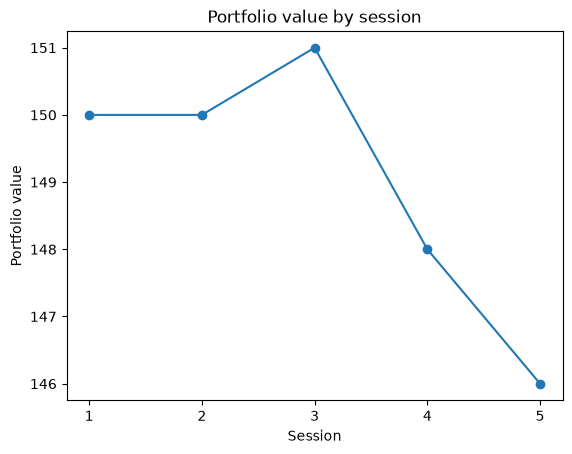

In [43]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

initial_cash = 150
market_prices = [
    {"ALFA": 100, "BETA": 50},
    {"ALFA": 102, "BETA": 51},
    {"ALFA": 103, "BETA": 47},
    {"ALFA": 100, "BETA": 49},
    {"ALFA": 98, "BETA": 47},
]
decisions = pd.DataFrame(simulate(market_prices, initial_cash))
if decisions.empty:
    print("Shto një seancë pas çmimeve të referencës për të marrë vendime.")
else:
    display(decisions)
    end_of_session = decisions.groupby("Seanca")["Vlera e portofolit"].last()
    print(f"Vlera përfundimtare e portofolit: {end_of_session.iloc[-1]}")
    plt.plot([1, *end_of_session.index], [initial_cash, *end_of_session], marker="o")
    plt.xlabel("Session")
    plt.ylabel("Portfolio value")
    plt.title("Portfolio value by session")
    plt.xticks([1, *end_of_session.index])
    plt.show()

## Kontrollet

In [44]:
assert stock_agent.perceive_and_act(MarketPerception(100, 102, 102, 0)) == "Bli"
assert stock_agent.perceive_and_act(MarketPerception(100, 102, 101, 0)) == "Prit"
assert stock_agent.perceive_and_act(MarketPerception(100, 98, 0, 1)) == "Shit"
assert stock_agent.perceive_and_act(MarketPerception(100, 98, 0, 0)) == "Prit"
assert stock_agent.perceive_and_act(MarketPerception(100, 101, 200, 1)) == "Prit"

scenario = [{"B": 100, "A": 100}, {"B": 102, "A": 102}, {"B": 103, "A": 98}]
trace = simulate(scenario, initial_cash=102)
assert [(row["Simboli"], row["Veprimi"]) for row in trace] == [
    ("A", "Bli"), ("B", "Prit"), ("A", "Shit"), ("B", "Prit"),
]
assert [row["Para pas veprimit"] for row in trace] == [0, 0, 98, 98]
assert [row["Aksione pas veprimit"] for row in trace] == [1, 0, 0, 0]
assert trace[-1]["Vlera e portofolit"] == 98
assert simulate([{"A": 100}], initial_cash=0) == []

for invalid_prices, invalid_cash in (
    ([], 100),
    ([{"A": 0}], 100),
    ([{"A": 100}, {"B": 100}], 100),
    ([{"A": 100}], -1),
):
    try:
        simulate(invalid_prices, invalid_cash)
    except ValueError:
        pass
    else:
        raise AssertionError("Invalid simulation input was accepted.")

print("Kontrollet kaluan.")

Kontrollet kaluan.


## Të dhëna të bursës nga Yahoo Finance

Pas `uv sync --locked` nga rrënja e projektit, përdor interpretuesin `.venv` si kernel dhe ekzekuto të gjitha qelizat. Kliko **Nis përditësimin** për të provuar agjentin me AAPL dhe një portofol të simuluar prej 1 000 USD. Për të zgjedhur një aksion tjetër, ndrysho `live_symbol` në qelizën e kontrolleve. Përdor një simbol që kuotohet në USD.

Grafiku shfaq deri në 30 çmime të fundit të marra nga Yahoo Finance. Kontrolli kërkon kuotën më të fundit afërsisht çdo 10 sekonda, për deri në 60 kërkesa ose derisa të klikosh **Ndalo**. Grafiku dhe agjenti përditësohen vetëm kur Yahoo kthen një kuotë me kohë më të re. Kuotat mund të vonohen dhe gjatë mbylljes së tregut mund të mos ketë vëzhgime të reja.

Çmimi i parë shërben si referencë. Për çdo kuotë të re, agjenti krahason çmimin me vëzhgimin e fundit dhe vendos **Bli**, **Shit** ose **Prit**. Pragu i shembullit është 0,01% (1 pikë bazë). Ndrysho `live_threshold_bps` për të provuar pragje të tjera. Çdo nisje krijon një portofol të ri të simuluar.

Grafiku dhe tabela përdorin USD dhe kohën UTC të kuotës.

In [45]:
import asyncio
from decimal import ROUND_HALF_UP, Decimal
from html import escape
from io import BytesIO
from math import isfinite

import ipywidgets as widgets
from matplotlib.dates import AutoDateLocator, DateFormatter
from matplotlib.figure import Figure


def quote_from_metadata(metadata):
    """Return Yahoo's most recent regular-session quote in UTC and cents."""
    timestamp = metadata.get("regularMarketTime")
    price = metadata.get("regularMarketPrice")
    if timestamp is None or price is None or not isfinite(price) or price <= 0:
        return None
    timestamp = pd.Timestamp(timestamp)
    if pd.isna(timestamp) or timestamp.tzinfo is None:
        return None
    cents = int((Decimal(str(price)) * 100).to_integral_value(rounding=ROUND_HALF_UP))
    if cents <= 0:
        return None
    return timestamp.tz_convert("UTC"), cents


def fetch_live_quote(ticker):
    bars = ticker.history(
        period="1d", interval="1m", auto_adjust=False, actions=False,
        timeout=8, raise_errors=True,
    )
    if bars.empty:
        return None
    return quote_from_metadata(ticker.history_metadata)


def record_quote(quotes, quote):
    """Append a new observation; repeated or older bars produce no decision."""
    if quote is None or (quotes and quote[0] <= quotes[-1][0]):
        return False
    quotes.append(quote)
    return True


def live_price_chart(symbol, quotes):
    timestamps, cents = zip(*quotes, strict=True)
    prices = [price / 100 for price in cents]
    figure = Figure(figsize=(7.2, 2.8), layout="constrained")
    axis = figure.subplots()
    axis.plot(timestamps, prices, color="#176b8a", linewidth=2)
    axis.scatter(timestamps[-1], prices[-1], color="#176b8a", zorder=3)
    axis.set_title(f"{symbol} · Latest sampled prices", loc="left")
    axis.set_xlabel("Time (UTC)")
    axis.set_ylabel("Price (USD)")
    axis.ticklabel_format(axis="y", style="plain", useOffset=False)
    if len(quotes) == 1:
        axis.set_xticks(timestamps)
    else:
        axis.xaxis.set_major_locator(AutoDateLocator(minticks=3, maxticks=6, tz="UTC"))
    axis.xaxis.set_major_formatter(DateFormatter("%H:%M:%S", tz="UTC"))
    axis.grid(axis="y", alpha=0.25)
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=120)
        return buffer.getvalue()

In [48]:
def live_controls(symbol, initial_cash_cents, threshold_bps):
    agent = make_stock_agent(threshold_bps)
    start = widgets.Button(description="Nis përditësimin")
    stop = widgets.Button(description="Ndalo", disabled=True)
    status = widgets.HTML()
    chart = widgets.Image(format="png", layout=widgets.Layout(width="100%", max_width="720px"))
    chart.layout.display = "none"
    results = widgets.HTML()
    stop_requested = asyncio.Event()

    async def follow_quotes(ticker):
        quotes = []
        loop = asyncio.get_running_loop()
        money_columns = [
            "Çmimi i mëparshëm", "Çmimi", "Para para veprimit",
            "Para pas veprimit", "Vlera e portofolit",
        ]
        try:
            for attempt in range(60):
                if stop_requested.is_set():
                    break
                refresh_at = loop.time() + 10
                try:
                    quote = await asyncio.to_thread(fetch_live_quote, ticker)
                except Exception as error:
                    status.value = f"Burimi i të dhënave nuk u përgjigj. {escape(str(error))}"
                else:
                    if stop_requested.is_set():
                        break
                    if record_quote(quotes, quote):
                        chart.value = live_price_chart(symbol, quotes[-30:])
                        chart.layout.display = ""
                        timestamp, cents = quotes[-1]
                        status.value = f"{symbol} · {timestamp:%Y-%m-%d %H:%M:%S} UTC · {cents / 100:.2f} USD"
                        trace = simulate(
                            [{symbol: price} for _, price in quotes], initial_cash_cents, agent=agent,
                        )
                        if trace:
                            table = pd.DataFrame(trace).drop(columns="Seanca")
                            table.insert(0, "Koha (UTC)", [t.strftime("%Y-%m-%d %H:%M:%S") for t, _ in quotes[1:]])
                            table[money_columns] = table[money_columns] / 100
                            results.value = table.to_html(index=False, float_format="{:.2f}".format)
                        else:
                            status.value += " · Çmimi i referencës"
                    elif quotes:
                        status.value = f"Pa kuotë të re. E fundit: {quotes[-1][0]:%Y-%m-%d %H:%M:%S} UTC."
                    else:
                        status.value = "Burimi nuk ktheu një kuotë të vlefshme."

                if attempt < 59:
                    try:
                        await asyncio.wait_for(
                            stop_requested.wait(), timeout=max(0, refresh_at - loop.time()),
                        )
                    except TimeoutError:
                        pass
            status.value += " · Përditësimi përfundoi."
        finally:
            start.disabled = False
            stop.disabled = True

    def on_start(_button):
        if start.disabled:
            return
        try:
            import yfinance as yf
        except ModuleNotFoundError as error:
            status.value = (
                f"Mungon moduli <code>{escape(str(error.name))}</code> në kernel. "
                "Nga rrënja e projektit ekzekuto <code>uv sync --locked</code>, "
                "zgjidh interpretuesin <code>.venv</code> dhe rinis kernelin."
            )
            return
        stop_requested.clear()
        start.disabled = True
        stop.disabled = False
        status.value = "Po lexohen çmimet…"
        chart.layout.display = "none"
        results.value = ""
        asyncio.create_task(follow_quotes(yf.Ticker(symbol)))

    def on_stop(_button=None):
        stop_requested.set()
        stop.disabled = True

    start.on_click(on_start)
    stop.on_click(on_stop)
    return widgets.VBox([widgets.HBox([start, stop]), status, chart, results]), on_stop


live_symbol = "AAPL"
live_threshold_bps = 1
previous_stop = globals().get("stop_live")
if previous_stop is not None:
    previous_stop()
live_panel, stop_live = live_controls(
    live_symbol, initial_cash_cents=100_000, threshold_bps=live_threshold_bps,
)
display(live_panel)

### Kontrollet e përditësimit

In [49]:
first_time = pd.Timestamp("2026-01-05 10:00:00", tz="America/New_York")
next_time = first_time + pd.Timedelta(seconds=10)
first_quote = quote_from_metadata({"regularMarketTime": first_time, "regularMarketPrice": 100.005})
next_quote = quote_from_metadata({"regularMarketTime": next_time, "regularMarketPrice": 102.1})
assert first_quote == (pd.Timestamp("2026-01-05 15:00:00", tz="UTC"), 10_001)
assert next_quote == (pd.Timestamp("2026-01-05 15:00:10", tz="UTC"), 10_210)
assert quote_from_metadata({}) is None
assert quote_from_metadata({"regularMarketTime": first_time, "regularMarketPrice": float("nan")}) is None
recent_quotes = [first_quote, next_quote]
assert live_price_chart(live_symbol, recent_quotes).startswith(bytes.fromhex("89504e470d0a1a0a"))
observations = []
assert record_quote(observations, first_quote)
assert record_quote(observations, next_quote)
assert not record_quote(observations, next_quote)
assert not record_quote(observations, first_quote)
assert not record_quote(observations, None)
live_trace = simulate([{live_symbol: cents} for _, cents in observations], 100_000)
assert [decision["Veprimi"] for decision in live_trace] == ["Bli"]
small_moves = [{live_symbol: cents} for cents in (100_000, 100_010, 99_999)]
minute_trace = simulate(small_moves, 200_000, agent=make_stock_agent(threshold_bps=live_threshold_bps))
assert [row["Veprimi"] for row in minute_trace] == ["Bli", "Shit"]
assert minute_trace[-1]["Para pas veprimit"] == 199_989
assert [row["Veprimi"] for row in simulate(small_moves, 200_000)] == ["Prit", "Prit"]
print("Kontrollet e përditësimit kaluan.")

Kontrollet e përditësimit kaluan.
